# m15 - Uncertainty: Prediction Intervals and Class Probabilities

**Question.** How sure is a model estimate of the 1 km GAEZ index in a cell, and how sure is the crop recommendation that
follows from it? A map of point estimates hides where the models are guessing.

**Method.** Locally adaptive conformal intervals, calibrated on spatially held-out errors:

1. **Out-of-fold predictions.** ExtraTrees under pixel-grouped CV (5 folds), for the two input sets of m14: the 14 physical
   drivers, and the drivers plus the 23 Sentinel-2 statistics.
2. **Expected error.** A second ExtraTrees learns the size of the error from the same inputs (also out-of-fold), so the
   intervals widen where the model is less reliable.
3. **Interval** = prediction ± q x expected error, with q the conformal quantile of the normalised errors for a 90 % target.
   Coverage is checked honestly: q for the cells of one fold comes only from the errors of the other four folds. A
   constant-width interval (± a quantile of the absolute error) is the reference.
4. **Class probabilities.** The recommendation rule (highest index wins, 'Not recommended' below 5,000) is applied to 200
   plausible versions of each cell's ten indices: the prediction plus the normalised errors of a randomly drawn calibration
   cell, all ten crops of that cell together so their correlation is kept. The share of versions that ends in each label is
   its probability. The probabilities are checked against the true GAEZ label (reliability, Brier score).

These describe the uncertainty of the *model estimate* from drivers and imagery, not an uncertainty of GAEZ itself.

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

In [2]:
df = E.load_table()
INPUTS = {"drivers": E.feature_columns(), "drivers + Sentinel-2": E.feature_columns() + E.FEATURE_GROUPS["sentinel2"]}
TAG = {"drivers": "drivers", "drivers + Sentinel-2": "s2"}           # column prefixes of the saved per-cell table
Y = df[E.gaez_cols()].to_numpy(float)
targets = {c: Y[:, j] for j, c in enumerate(E.CROPS)}
SPLITS = E.make_splits(df, "pixel", 5, seed=0)
fold = np.empty(len(df), dtype=int)
for k, (_, te) in enumerate(SPLITS):
    fold[te] = k
ALPHA = 0.10                                                        # 90 % intervals
LABELS = [E.CROPS[i] for i in range(len(E.CROPS))] + ["Not recommended"]
print(f"{len(df)} cells, {len(SPLITS)} pixel-grouped folds, target coverage {1 - ALPHA:.0%}")

9129 cells, 5 pixel-grouped folds, target coverage 90%


## 1. Out-of-fold predictions and expected errors

In [3]:
pred, sigma = {}, {}
for name, cols in INPUTS.items():
    _, oof = E.run_grid(df, targets, ["et"], [], columns=cols, custom_splits={"pixel": SPLITS}, keep_oof=True, verbose=False)
    pred[name] = np.column_stack([oof[("et", c, "pixel", 0)] for c in E.CROPS])
    X, A = df[cols].to_numpy(float), np.abs(Y - pred[name])
    s = np.zeros_like(A)
    for tr, te in SPLITS:     # cross-fitted: the error model of a fold never sees that fold
        m = make_pipeline(SimpleImputer(strategy="median"),
                          ExtraTreesRegressor(200, min_samples_leaf=20, max_features=0.5, n_jobs=E.N_JOBS, random_state=0))
        m.fit(X[tr], A[tr])
        s[te] = m.predict(X[te])
    sigma[name] = np.maximum(s, 1.0)
    r2 = 1 - ((Y - pred[name]) ** 2).sum(0) / ((Y - Y.mean(0)) ** 2).sum(0)
    rho = [E.spearman(A[:, j], sigma[name][:, j]) for j in range(Y.shape[1])]
    print(f"{name:22s} mean R2 {r2.mean():.3f} | Spearman(|error|, expected error) {np.mean(rho):.2f}")

drivers                mean R2 0.819 | Spearman(|error|, expected error) 0.56


drivers + Sentinel-2   mean R2 0.865 | Spearman(|error|, expected error) 0.55


## 2. Conformal intervals and their coverage

`coverage` is the share of cells whose true 1 km GAEZ index falls inside its interval (target 0.90); `mean width` is in
index points (0-10,000).

In [4]:
def conformal_q(scores, alpha):
    n = len(scores)
    return np.quantile(scores, min(1.0, np.ceil((n + 1) * (1 - alpha)) / n), method="higher")


rows, bounds = [], {}
for name in INPUTS:
    err = Y - pred[name]
    score = np.abs(err) / sigma[name]
    lo, hi, lo_c, hi_c = (np.zeros_like(Y) for _ in range(4))
    for k in range(len(SPLITS)):
        cal, test = fold != k, fold == k
        for j in range(Y.shape[1]):
            q = conformal_q(score[cal, j], ALPHA)
            qc = conformal_q(np.abs(err[cal, j]), ALPHA)
            lo[test, j] = pred[name][test, j] - q * sigma[name][test, j]
            hi[test, j] = pred[name][test, j] + q * sigma[name][test, j]
            lo_c[test, j], hi_c[test, j] = pred[name][test, j] - qc, pred[name][test, j] + qc
    lo, hi, lo_c, hi_c = (np.clip(a, 0, 10000) for a in (lo, hi, lo_c, hi_c))
    bounds[name] = (lo, hi)
    for j, c in enumerate(E.CROPS):
        for kind, l, h in [("adaptive", lo, hi), ("constant width", lo_c, hi_c)]:
            inside = (Y[:, j] >= l[:, j]) & (Y[:, j] <= h[:, j])
            rows.append({"inputs": name, "interval": kind, "crop": c, "coverage": inside.mean(),
                         "mean width": (h[:, j] - l[:, j]).mean(), "median width": np.median(h[:, j] - l[:, j])})
coverage = pd.DataFrame(rows)
E.save_table(coverage.round(4), "m15_coverage")
coverage.groupby(["inputs", "interval"])[["coverage", "mean width", "median width"]].mean().round(3)

coverage  mean width  median width
inputs               interval                                          
drivers              adaptive           0.899    2025.313      1790.861
                     constant width     0.898    2342.137      2449.945
drivers + Sentinel-2 adaptive           0.899    1852.372      1678.611
                     constant width     0.899    2124.546      2238.612

In [5]:
# Does the coverage hold in every kind of landscape? (conditional coverage by majority land cover, mean over crops)
lc_names = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland", 50: "Built-up", 60: "Bare / sparse",
            80: "Water", 90: "Wetland", 95: "Mangroves"}
lc = df["landcover_majority"].map(lc_names).fillna("other").to_numpy()
rows = []
for name in INPUTS:
    lo, hi = bounds[name]
    err_c = np.abs(Y - pred[name])
    qc_all = np.array([conformal_q(err_c[:, j], ALPHA) for j in range(Y.shape[1])])
    for g in pd.unique(lc):
        m = lc == g
        rows.append({"inputs": name, "land cover": g, "cells": int(m.sum()),
                     "coverage, adaptive": ((Y[m] >= lo[m]) & (Y[m] <= hi[m])).mean(),
                     "coverage, constant width": (np.abs(Y[m] - pred[name][m]) <= qc_all).mean(),
                     "mean width, adaptive": (hi[m] - lo[m]).mean()})
by_lc = pd.DataFrame(rows).sort_values(["inputs", "cells"], ascending=[True, False])
E.save_table(by_lc.round(4), "m15_coverage_by_landcover")
by_lc[by_lc["cells"] >= 50].round(3)

,inputs,land cover,cells,"coverage, adaptive","coverage, constant width","mean width, adaptive"
0,drivers,Tree cover,6816,0.907,0.949,1684.144
3,drivers,Cropland,1282,0.947,0.913,2396.618
2,drivers,Built-up,772,0.751,0.479,4147.153
1,drivers,Water,163,0.887,0.829,2618.763
4,drivers,Grassland,76,0.908,0.708,3353.466
8,drivers + Sentinel-2,Tree cover,6816,0.900,0.938,1606.779
11,drivers + Sentinel-2,Cropland,1282,0.925,0.920,1770.225
10,drivers + Sentinel-2,Built-up,772,0.869,0.575,3876.654
9,drivers + Sentinel-2,Water,163,0.846,0.814,2426.475
12,drivers + Sentinel-2,Grassland,76,0.818,0.654,3232.787


## 3. Class probabilities of the recommendation

In [6]:
def rule_label(values):
    """Index of the recommended label for an array (..., 10): best crop, or len(CROPS) = 'Not recommended' below 5,000."""
    return np.where(values.max(-1) >= E.NOT_RECOMMENDED_THRESHOLD, values.argmax(-1), len(E.CROPS))


M = 200
rng = np.random.default_rng(0)
proba, p_suit = {}, {}
truth = rule_label(Y)
for name in INPUTS:
    signed = (Y - pred[name]) / sigma[name]
    P, S = np.zeros((len(df), len(LABELS))), np.zeros_like(Y)
    for k in range(len(SPLITS)):
        cal, test = np.where(fold != k)[0], np.where(fold == k)[0]
        draws = rng.choice(cal, size=(len(test), M))            # whole calibration cells keep the cross-crop correlation
        sim = np.clip(pred[name][test, None, :] + signed[draws] * sigma[name][test, None, :], 0, 10000)
        lab = rule_label(sim)
        P[test] = np.stack([(lab == i).mean(axis=1) for i in range(len(LABELS))], axis=1)
        S[test] = (sim >= E.NOT_RECOMMENDED_THRESHOLD).mean(axis=1)
    proba[name], p_suit[name] = P, S

rows = []
for name in INPUTS:
    P = proba[name]
    onehot = np.eye(len(LABELS))[truth]
    point = rule_label(pred[name])
    rows.append({"inputs": name, "accuracy of the most likely label": (P.argmax(1) == truth).mean(),
                 "accuracy of the point-estimate label": (point == truth).mean(),
                 "Brier score (labels)": ((P - onehot) ** 2).sum(1).mean(),
                 "mean probability of the true label": P[np.arange(len(df)), truth].mean(),
                 "Brier score (suitable, per crop)": ((p_suit[name] - (Y >= E.NOT_RECOMMENDED_THRESHOLD)) ** 2).mean()})
probs = pd.DataFrame(rows).set_index("inputs")
E.save_table(probs.round(4), "m15_probability_scores", index=True)
probs.round(3)

,accuracy of the most likely label,accuracy of the point-estimate label,Brier score (labels),mean probability of the true label,"Brier score (suitable, per crop)"
inputs,,,,,
drivers,0.819,0.814,0.252,0.745,0.048
drivers + Sentinel-2,0.828,0.823,0.245,0.758,0.042


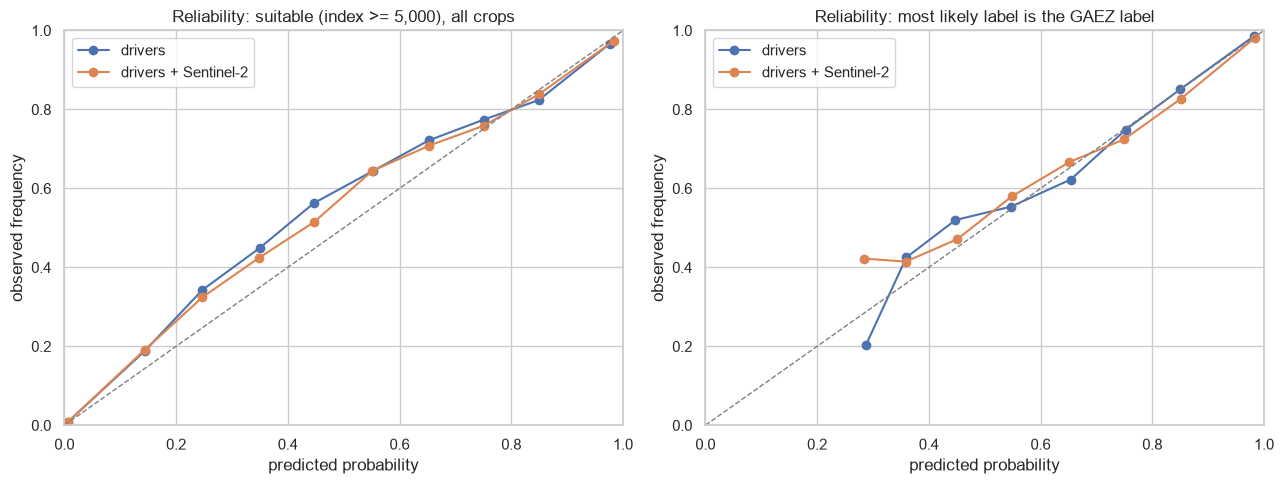

In [7]:
# Reliability: among cells given a probability of about p, is the event true about p of the time?
bins = np.linspace(0, 1, 11)
rows = []
for name in INPUTS:
    for what, prob, event in [("suitable (index >= 5,000), all crops", p_suit[name].ravel(),
                               (Y >= E.NOT_RECOMMENDED_THRESHOLD).ravel()),
                              ("most likely label is the GAEZ label", proba[name].max(1), proba[name].argmax(1) == truth)]:
        b = np.clip(np.digitize(prob, bins) - 1, 0, len(bins) - 2)
        for i in range(len(bins) - 1):
            m = b == i
            if m.sum() >= 20:
                rows.append({"inputs": name, "event": what, "predicted": prob[m].mean(), "observed": event[m].mean(),
                             "n": int(m.sum())})
rel = pd.DataFrame(rows)
E.save_table(rel.round(4), "m15_reliability")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, what in zip(axes, rel["event"].unique()):
    for name, g in rel[rel["event"] == what].groupby("inputs"):
        ax.plot(g["predicted"], g["observed"], marker="o", label=name)
    ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1)
    ax.set(title=f"Reliability: {what}", xlabel="predicted probability", ylabel="observed frequency", xlim=(0, 1), ylim=(0, 1))
    ax.legend()
plt.tight_layout()
E.save_fig(fig, "m15_reliability")
plt.show()

## 4. Coverage, width and maps

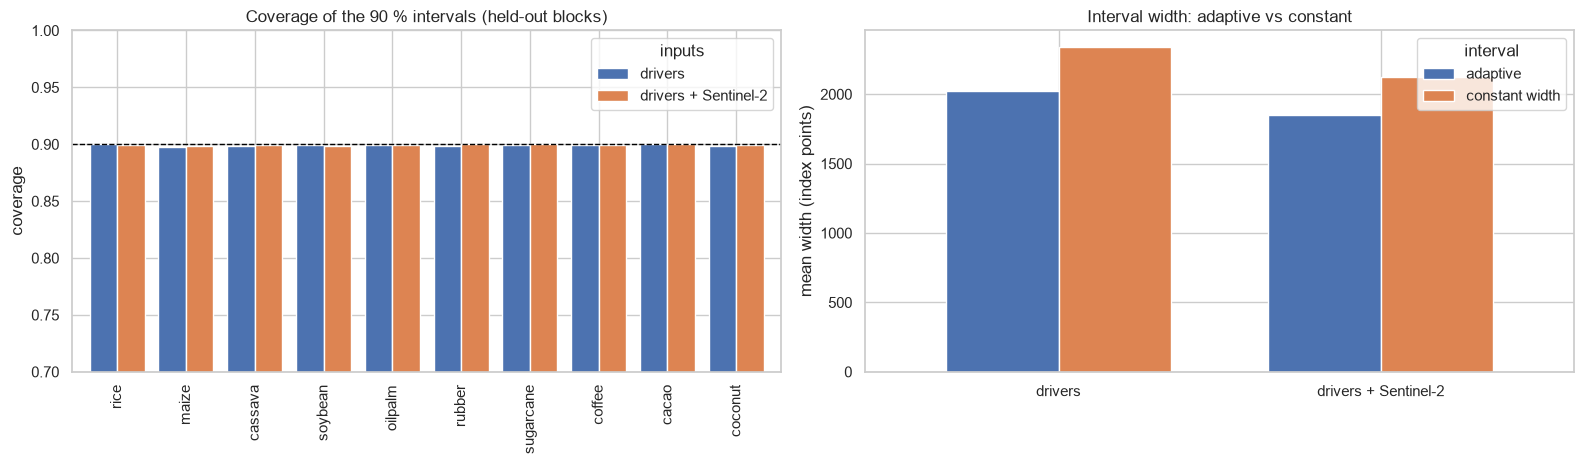

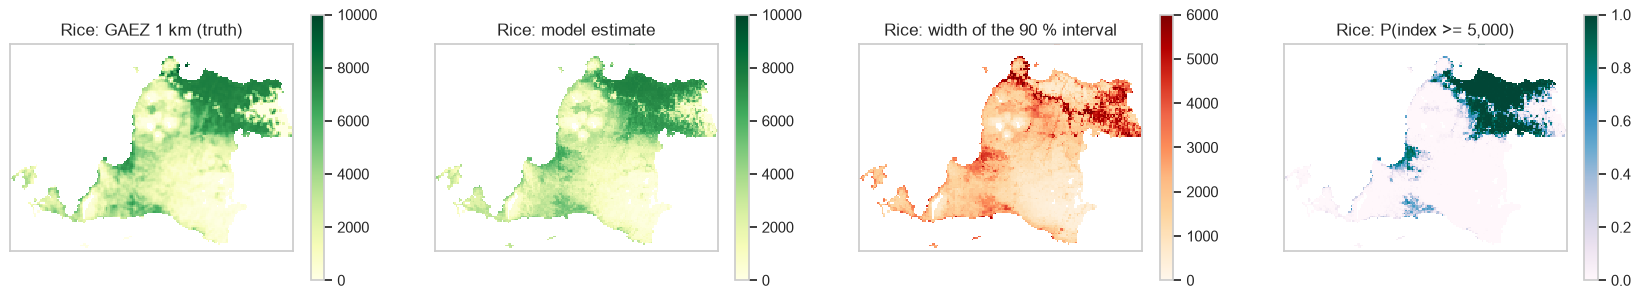

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
ad = coverage[coverage["interval"] == "adaptive"]
ad.pivot(index="crop", columns="inputs", values="coverage").reindex(E.CROPS).plot.bar(ax=axes[0], width=0.8)
axes[0].axhline(1 - ALPHA, color="black", ls="--", lw=1)
axes[0].set(ylim=(0.7, 1), ylabel="coverage", xlabel="", title="Coverage of the 90 % intervals (held-out blocks)")
coverage.groupby(["inputs", "interval"])["mean width"].mean().unstack("interval").plot.bar(ax=axes[1], width=0.7, rot=0)
axes[1].set(ylabel="mean width (index points)", xlabel="", title="Interval width: adaptive vs constant")
plt.tight_layout()
E.save_fig(fig, "m15_coverage")
plt.show()

name, crop = "drivers + Sentinel-2", "rice"
j = E.CROPS.index(crop)
lo, hi = bounds[name]
shape = (df["row"].max() + 1, df["col"].max() + 1)


def on_grid(values):
    z = np.full(shape, np.nan)
    z[df["row"].to_numpy(), df["col"].to_numpy()] = values
    return z


panels = [(Y[:, j], "GAEZ 1 km (truth)", "YlGn", (0, 10000)), (pred[name][:, j], "model estimate", "YlGn", (0, 10000)),
          (hi[:, j] - lo[:, j], "width of the 90 % interval", "OrRd", (0, 6000)),
          (p_suit[name][:, j], "P(index >= 5,000)", "PuBuGn", (0, 1))]
fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))
for ax, (v, title, cmap, (vmin, vmax)) in zip(axes, panels):
    im = ax.imshow(on_grid(v), origin="lower", cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set(title=f"Rice: {title}")
    ax.set_xticks([])
    ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.75)
E.save_fig(fig, "m15_maps_rice")
plt.show()

## 5. Save the per-cell results for the dashboard

In [9]:
out = {"grid_id": df["grid_id"].to_numpy()}
for name in INPUTS:
    lo, hi = bounds[name]
    for j, c in enumerate(E.CROPS):
        out[f"{TAG[name]}__pred__{c}"] = pred[name][:, j]
        out[f"{TAG[name]}__lo__{c}"] = lo[:, j]
        out[f"{TAG[name]}__hi__{c}"] = hi[:, j]
        out[f"{TAG[name]}__psuit__{c}"] = p_suit[name][:, j]
    for i, label in enumerate(LABELS):
        out[f"{TAG[name]}__plabel__{label}"] = proba[name][:, i]
cells = pd.DataFrame(out)
print(E.save_oof(cells, "m15_uncertainty"), cells.shape)

# Interval half-widths fitted on every cell, for new inputs (the AI Lab's what-if simulator): constant width per crop
qs = pd.DataFrame([{"inputs": name, "crop": c, "half_width": conformal_q(np.abs(Y[:, j] - pred[name][:, j]), ALPHA)}
                   for name in INPUTS for j, c in enumerate(E.CROPS)])
E.save_table(qs.round(1), "m15_quantiles")
qs.pivot(index="crop", columns="inputs", values="half_width").reindex(E.CROPS).round(0)

D:\Softwares\AnacondaProjects\GeoSuitability_AI_Analytics\datasets\processed\experiments\m15_uncertainty.parquet (9129, 103)


inputs,drivers,drivers + Sentinel-2
crop,,
rice,1401.0,1265.0
maize,685.0,613.0
cassava,1556.0,1399.0
soybean,801.0,759.0
oilpalm,1605.0,1475.0
rubber,607.0,565.0
sugarcane,1015.0,915.0
coffee,1621.0,1463.0
cacao,1329.0,1197.0
